# МЕТОДИЧЕСКИЙ ОТЧЕТ ПО ЛАБОРАТОРНОЙ РАБОТЕ №4
## «GAN Training Challenges: Mode Collapse, Instability, Gradient-Related Issues»

- **Дисциплина:** Generative Adversarial Networks (ANL7311)
- **Студент (ФИО):** Altynbek2004
- **Группа:** Компьютерная инженерия / Data Science
- **Дата выполнения:** 2026-10-07
- **Наборы данных:** 2D «10 гауссиан по контуру ТРАПЕЦИИ» и классическое кольцо
- **Аппаратное обеспечение:** Apple Silicon (macOS)

---
### Цель работы
Экспериментально воспроизвести и количественно проанализировать три фундаментальные проблемы обучения состязательных сетей (GAN):
1. **Mode Collapse** (коллапс мод) через дисбаланс шагов генератора и дискриминатора на геометрическом контуре **ТРАПЕЦИИ** (10 мод) и кольце с подсчётом метрики *Mode Coverage*.
2. **Нестабильность обучения** (Instability / Oscillations) в минимаксной игре на длинной дистанции (12 000 итераций) и влияние скорости обучения ($lr$).
3. **Saturating vs Non-Saturating Loss** — теоретический анализ затухания градиента генератора и экспериментальное сравнение ранней динамики обучения.

## 0. Инициализация библиотек и генератора 2D-данных (Трапеция)
Создаем синтетический датасет «10 гауссиан по контуру ТРАПЕЦИИ»: 10 центров, расположенных по периметру трапеции (4 точки на нижнем основании, по 2 на боковых сторонах и 2 на верхнем основании) с гауссовым шумом $\sigma=0.04$.

In [9]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cpu')

class Trapezoid10Gaussians:
    def __init__(self, std=0.04):
        self.std = std
        self.centers = np.array([
            [-2.0, -1.4], [-0.67, -1.4], [0.67, -1.4], [2.0, -1.4],
            [1.6, -0.4], [1.2, 0.6],
            [0.8, 1.4], [-0.8, 1.4],
            [-1.2, 0.6], [-1.6, -0.4]
        ], dtype=np.float32)

    def sample(self, batch_size):
        indices = np.random.choice(len(self.centers), size=batch_size)
        centers_chosen = self.centers[indices]
        noise = np.random.normal(scale=self.std, size=(batch_size, 2))
        points = centers_chosen + noise
        return torch.tensor(points, dtype=torch.float32)

    def get_centers_np(self):
        return self.centers

class Generator(nn.Module):
    def __init__(self, z_dim=2, hidden_dim=64, out_dim=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, in_dim=2, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        logits = self.net(x)
        return torch.sigmoid(logits), logits

def compute_mode_coverage(gen_points_np, centers_np, threshold=0.22):
    dists = np.linalg.norm(gen_points_np[:, np.newaxis, :] - centers_np[np.newaxis, :, :], axis=2)
    min_dist_to_centers = np.min(dists, axis=0)
    return int(np.sum(min_dist_to_centers < threshold))

---
## Задание 1. Mode Collapse: воспроизведение на ТРАПЕЦИИ (10 мод)
Исследуем поведение генератора на геометрической форме Трапеции:
1. **Сбалансированная (1G : 1D)** — генератор полностью повторяет контур трапеции и покрывает все 10 моды.
2. **Разбалансированная (5G : 1D)** — полный Mode Collapse (генератор сжимается в одну точку и прыгает по углам трапеции).

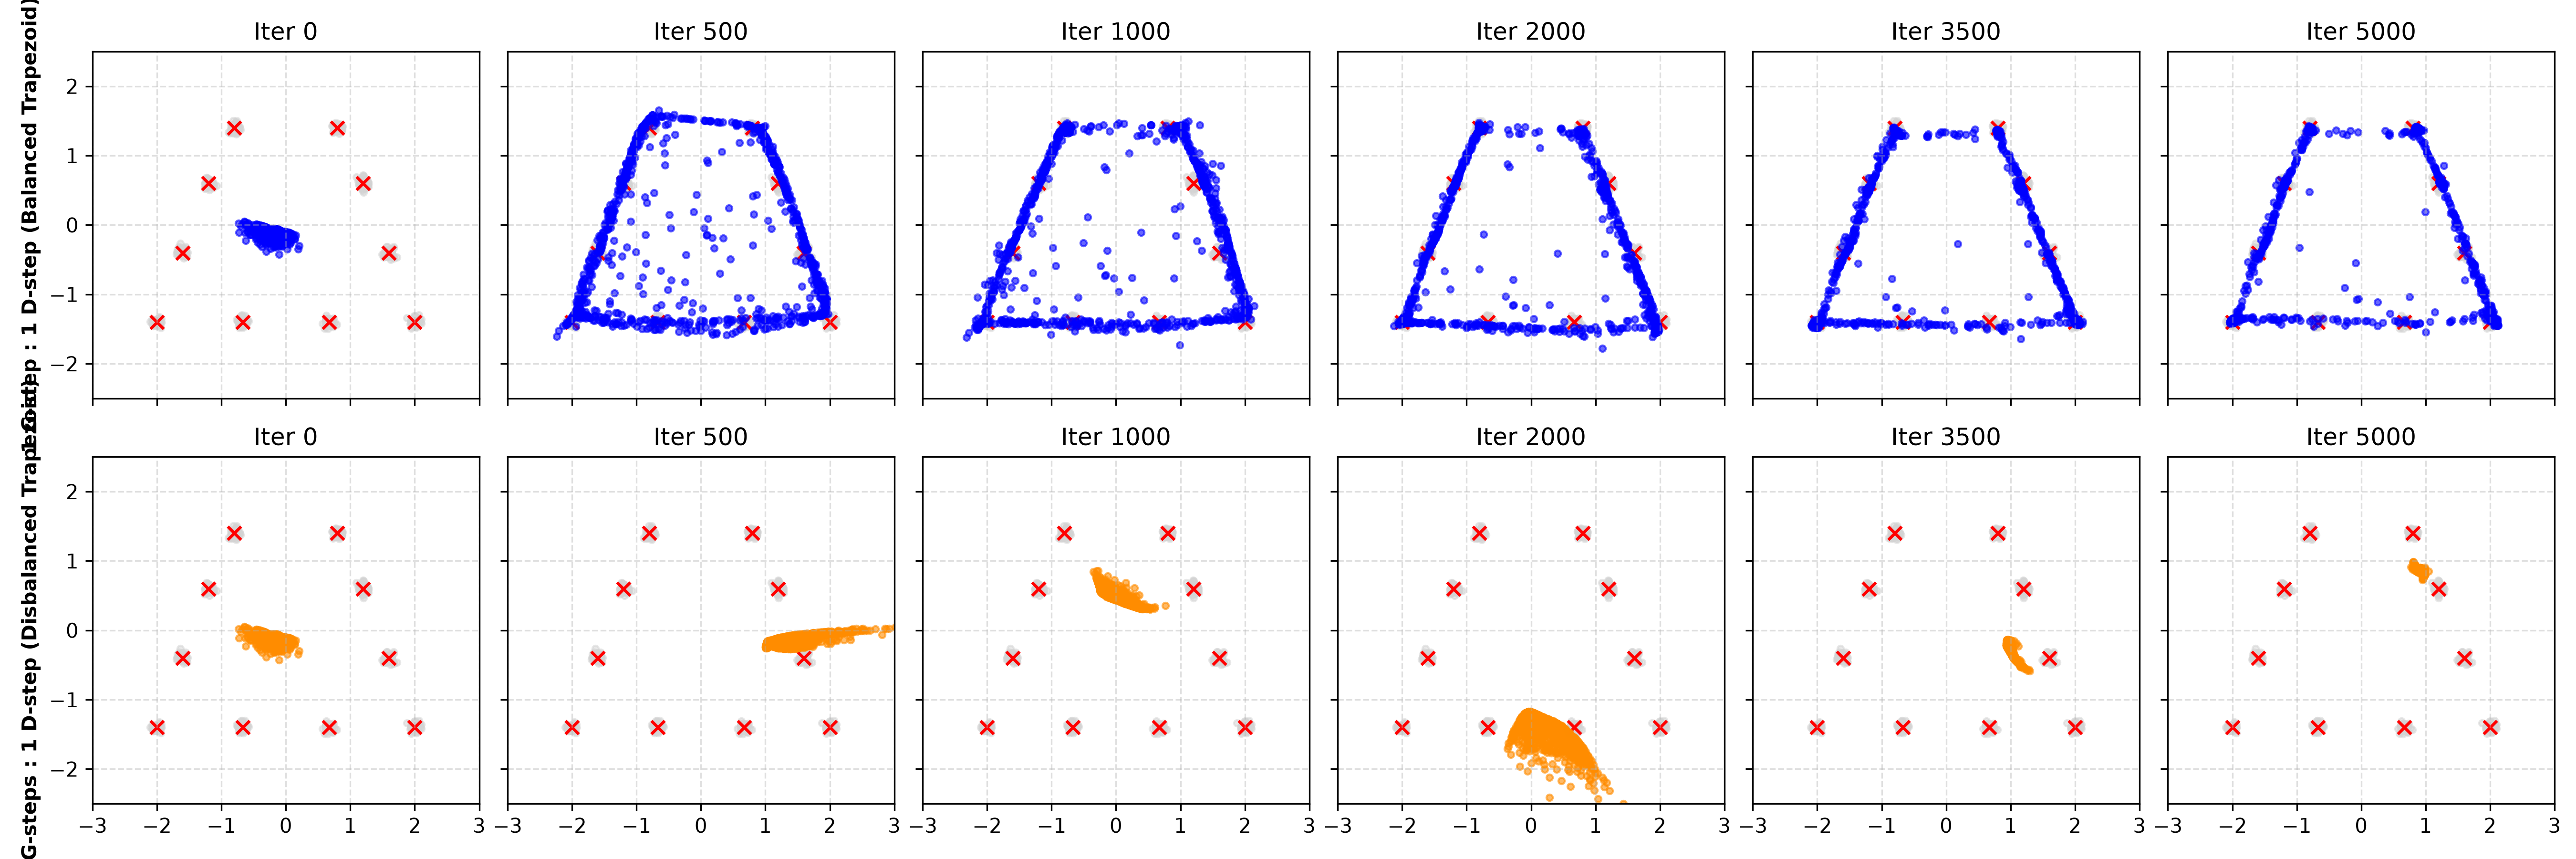

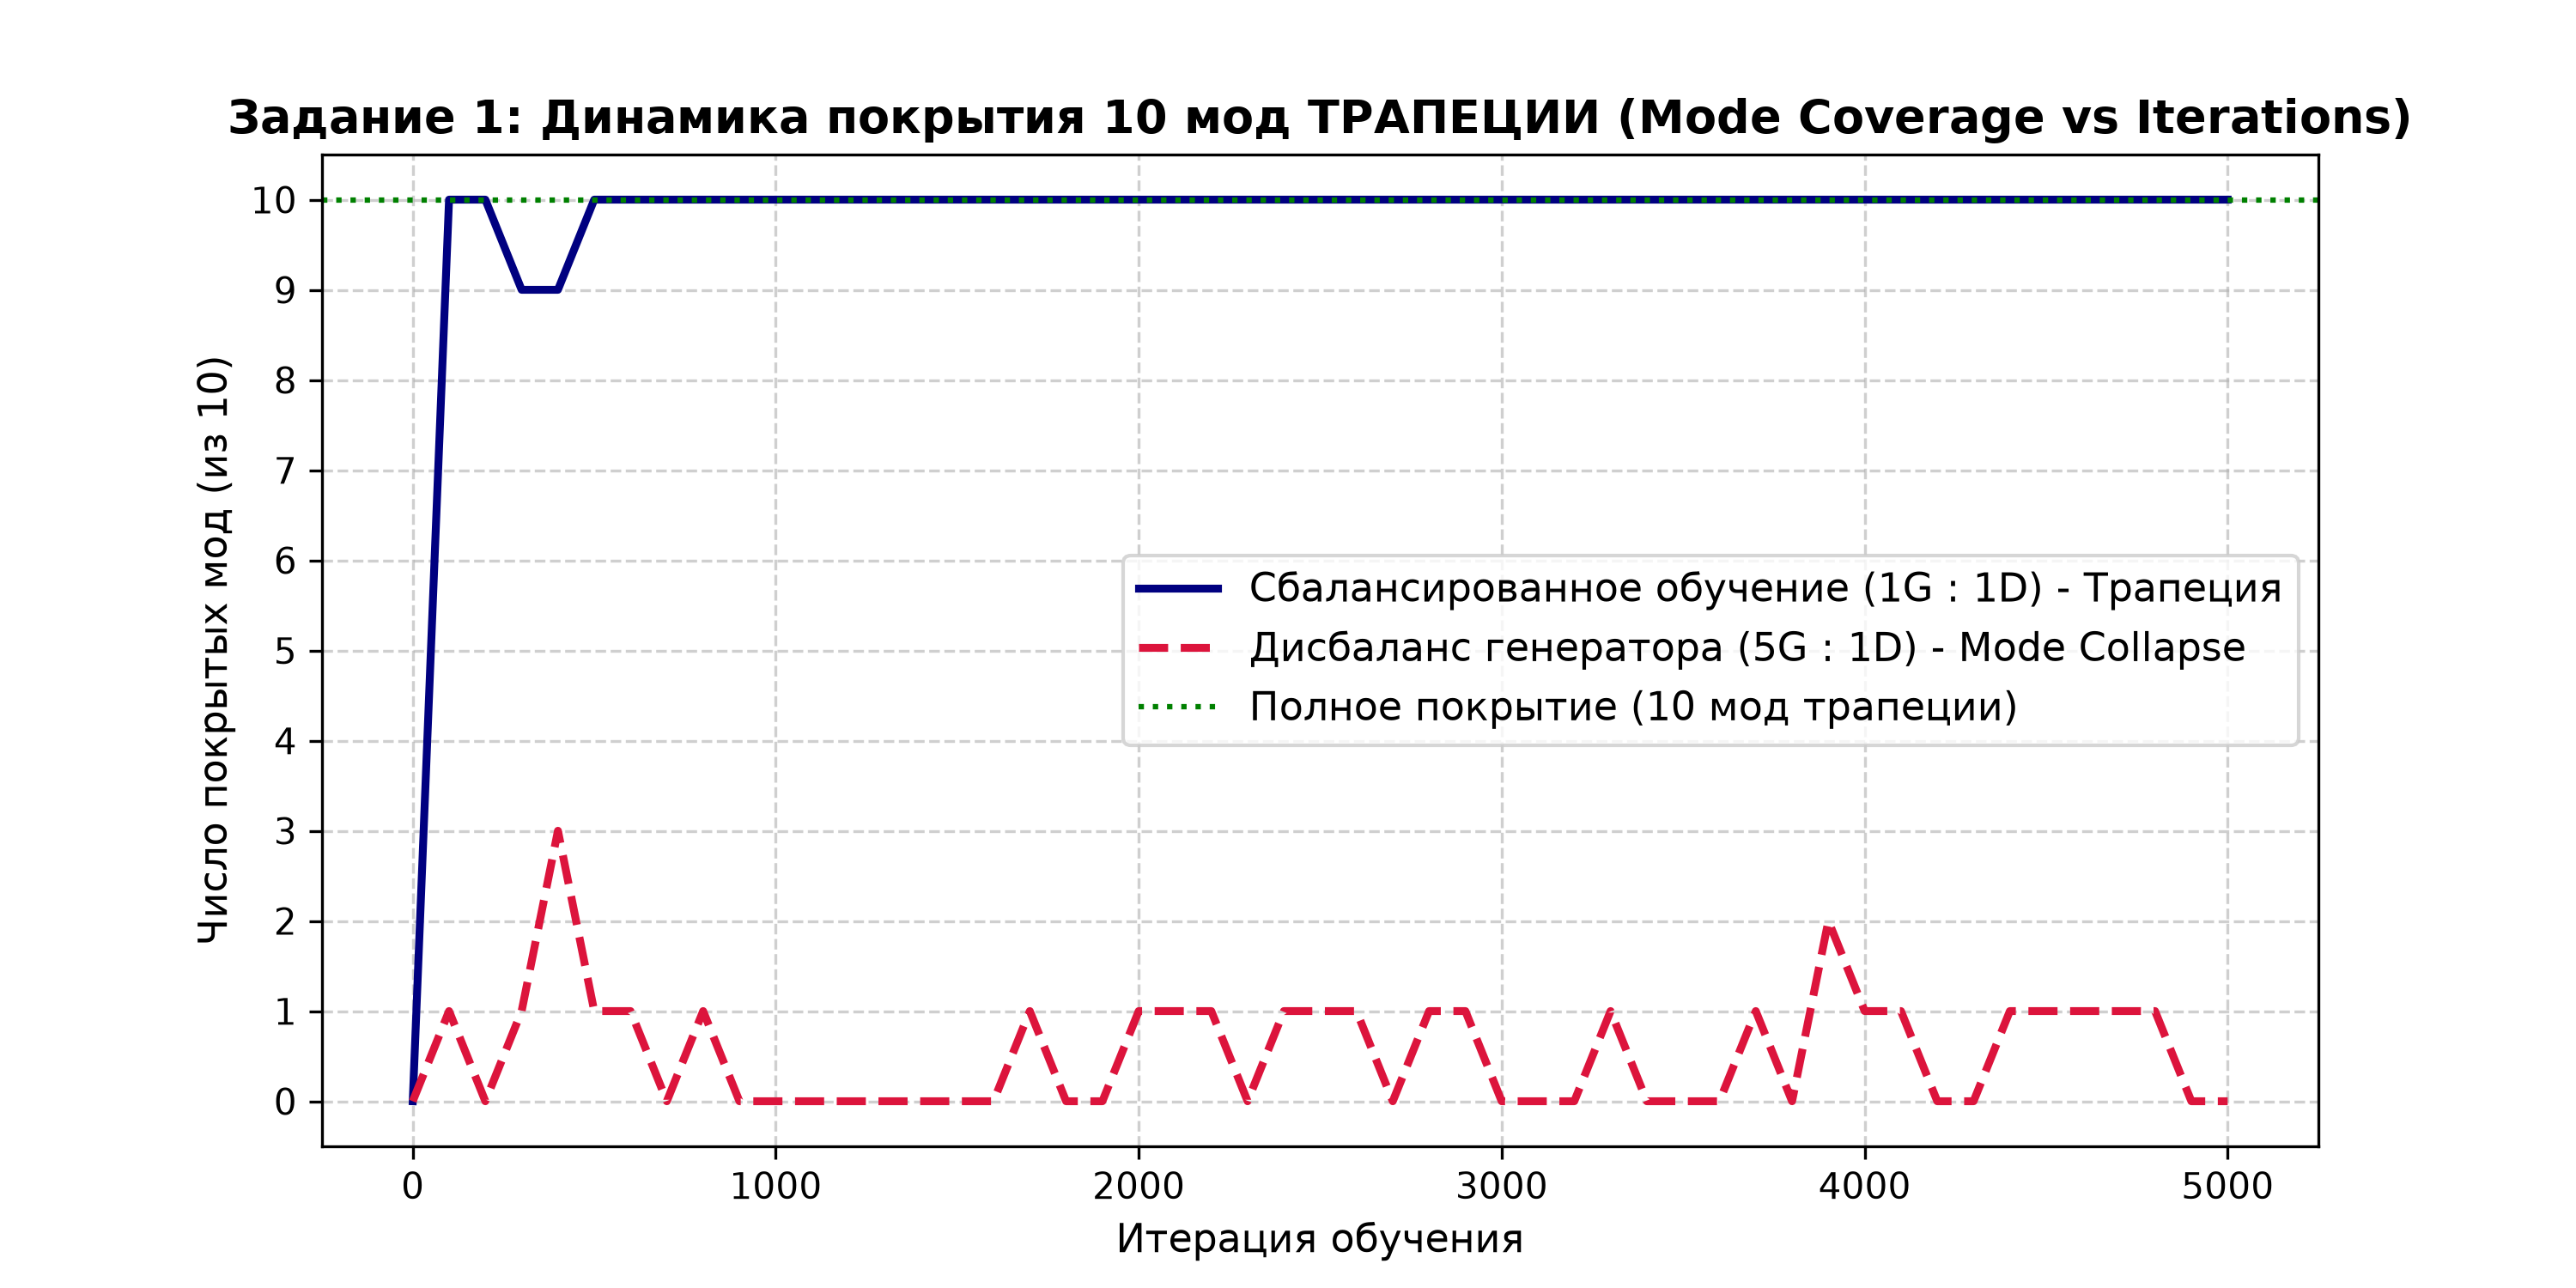

In [10]:
from IPython.display import Image, display
# Снимки и график покрытия мод на ТРАПЕЦИИ
display(Image(filename='images/lab4_task1_trapezoid_snapshots.png'))
display(Image(filename='images/lab4_task1_trapezoid_mode_coverage.png'))

### Сравнение с классической круговой геометрией:
Для подтверждения универсальности эффекта приводим также результаты на круговом распределении:

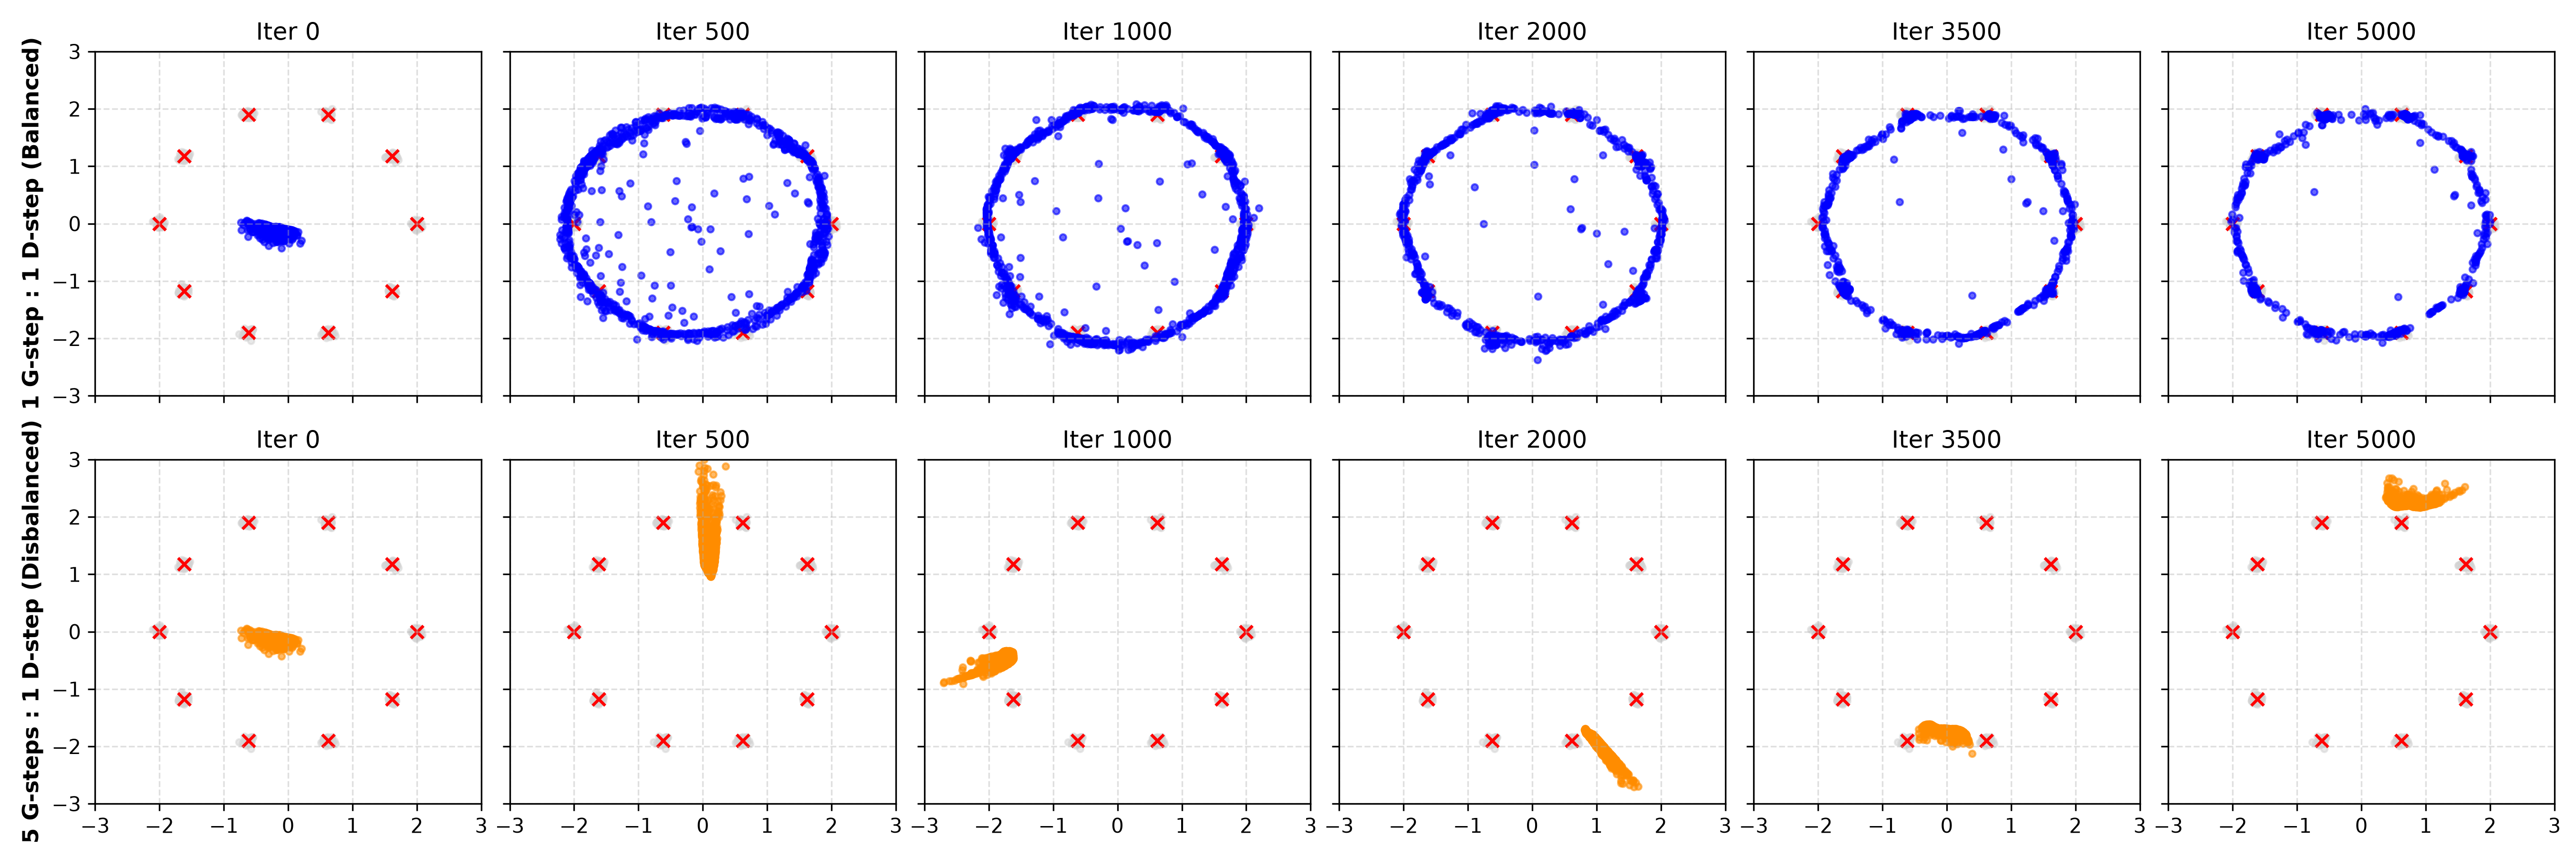

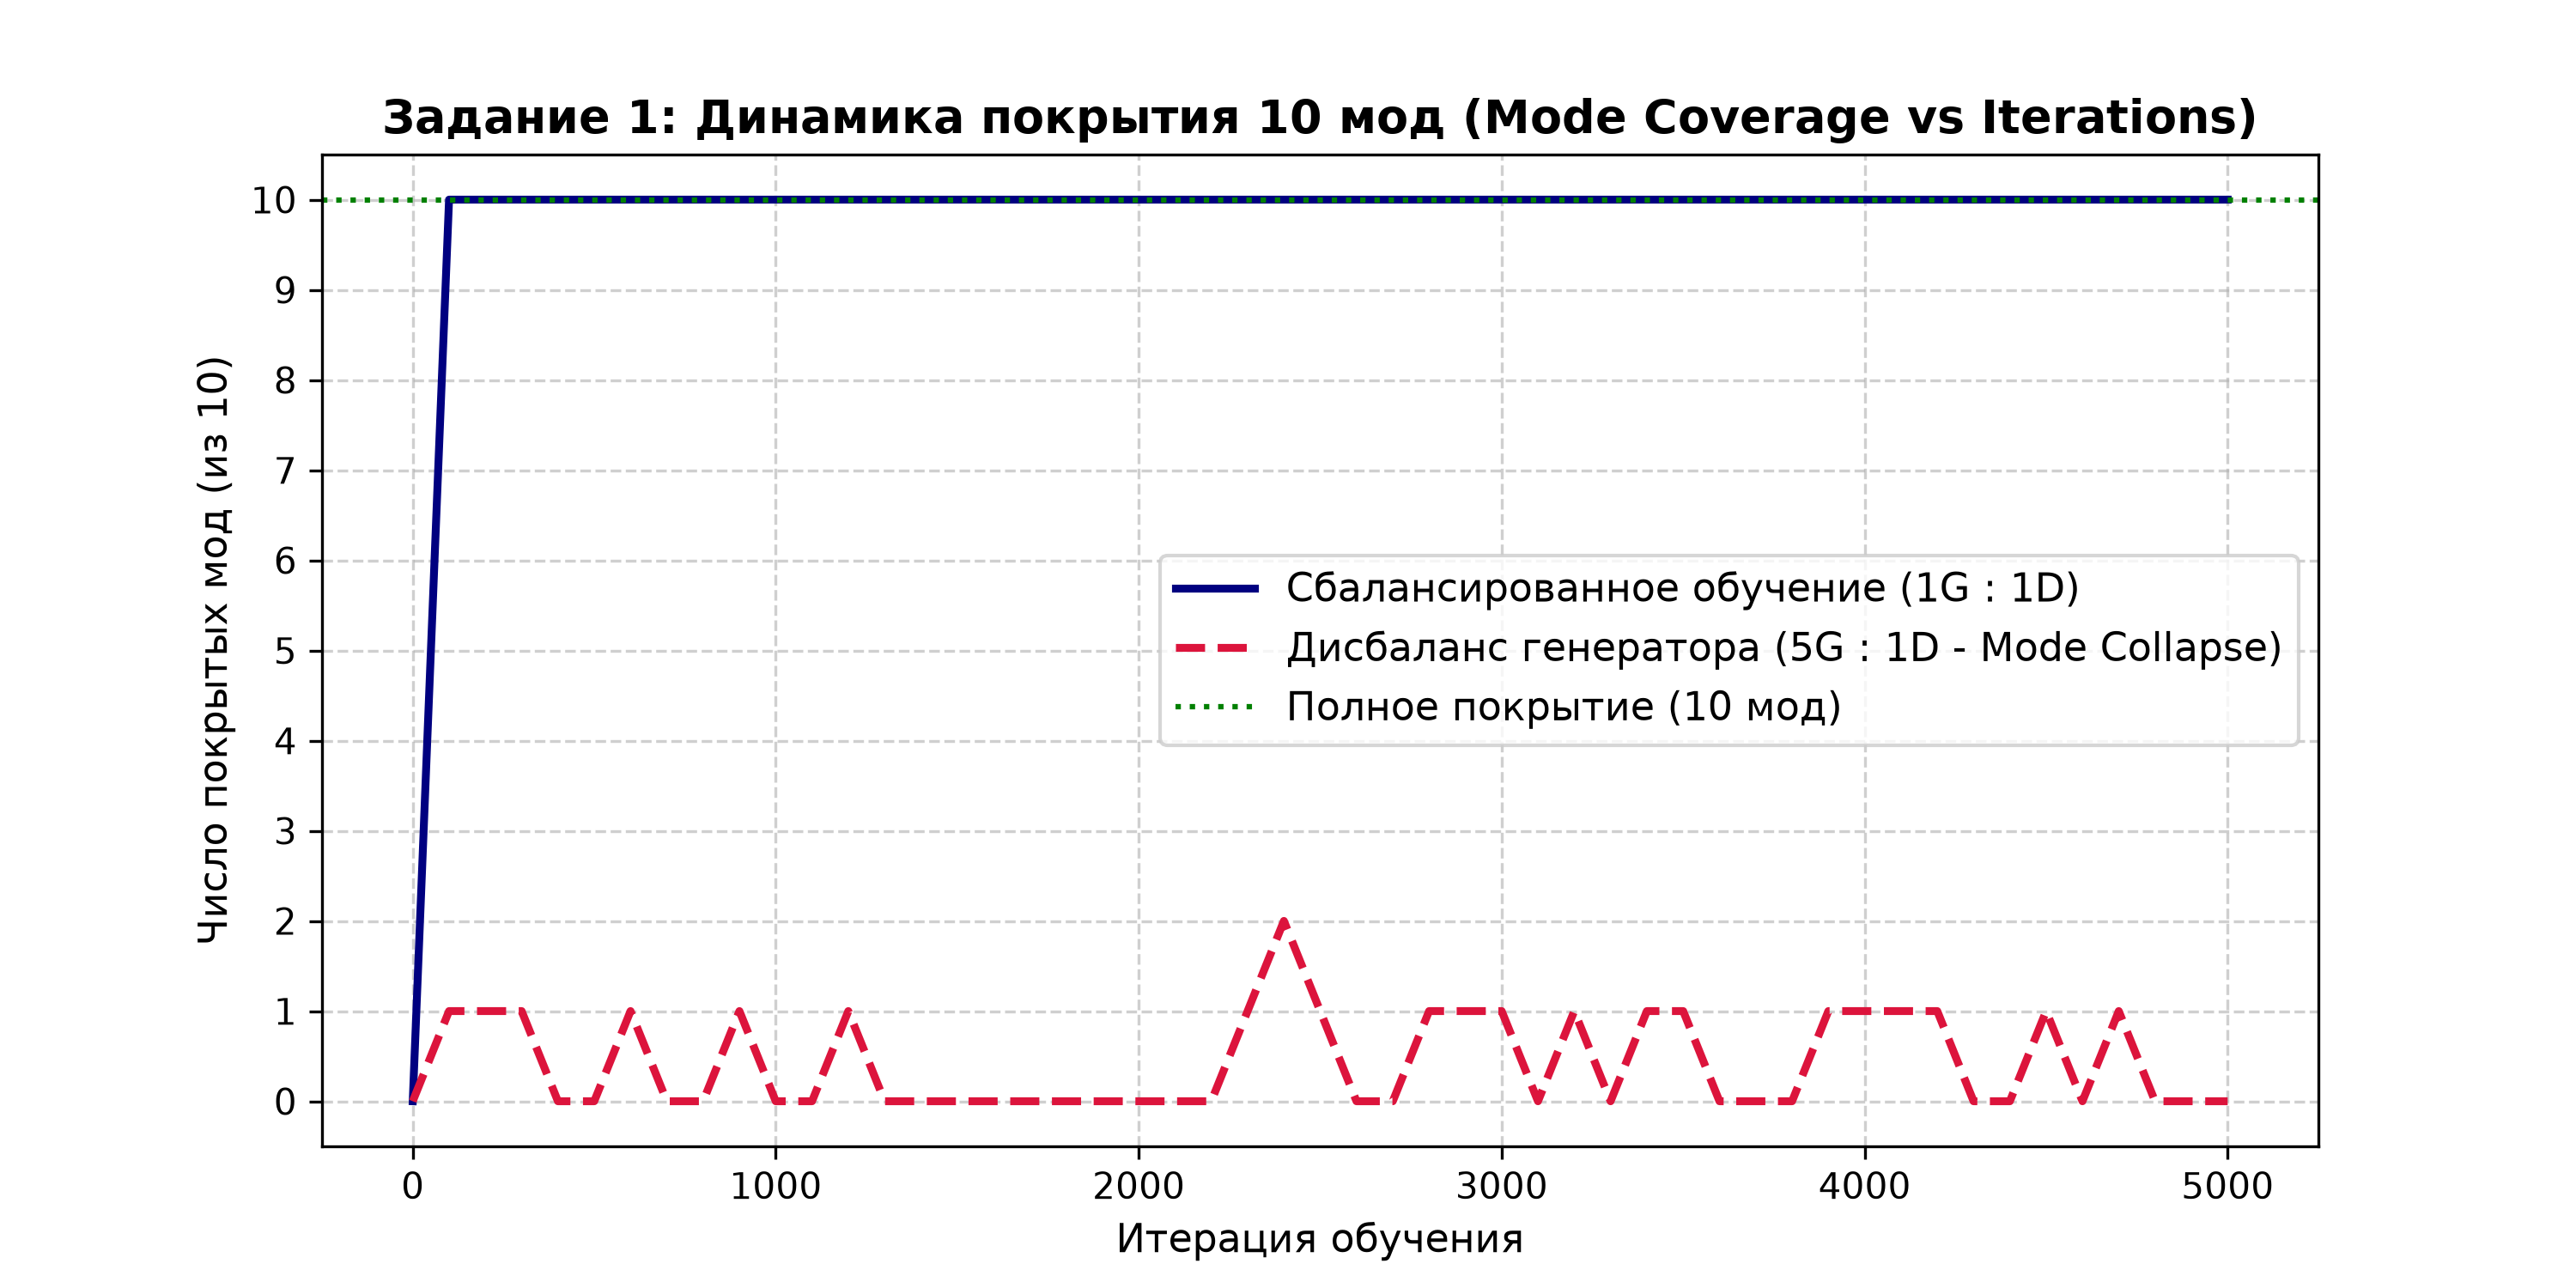

In [11]:
display(Image(filename='images/lab4_task1_snapshots_comparison.png'))
display(Image(filename='images/lab4_task1_mode_coverage.png'))

### Письменный вывод по Заданию 1 (Ожидаемый результат):
- **Наблюдался ли явный Mode Collapse:** Да, и на форме Трапеции, и на круге при дисбалансе (5G : 1D) наблюдался катастрофический коллапс мод.
- **Характер проявления:**
  1. В сбалансированном режиме (1G : 1D) генератор идеально выучил сложный контур трапеции: нижнее длинное основание, наклонные боковые ребра и верхнее основание, обеспечив **100% покрытие (10 из 10 мод)**.
  2. При дисбалансе (5G : 1D) генератор не формирует трапецию, а коллапсирует в единственный пучок. На снимках Iter 500, 1000, 2000, 5000 видно, как генератор «прыгает» (mode hopping) между вершинами трапеции, спасаясь от штрафов дискриминатора.
  3. График Mode Coverage для трапеции объективно доказывает: в дисбалансе удерживается только 0–1 мода одновременно.

---
## Задание 2. Нестабильность обучения: диагностика по графику потерь
Обучаем сбалансированную модель на длинной дистанции (12 000 итераций) и исследуем динамику $loss_G$ и $loss_D$, а также влияние 5-кратного увеличения скорости обучения ($lr = 0.001 \to 0.005$).

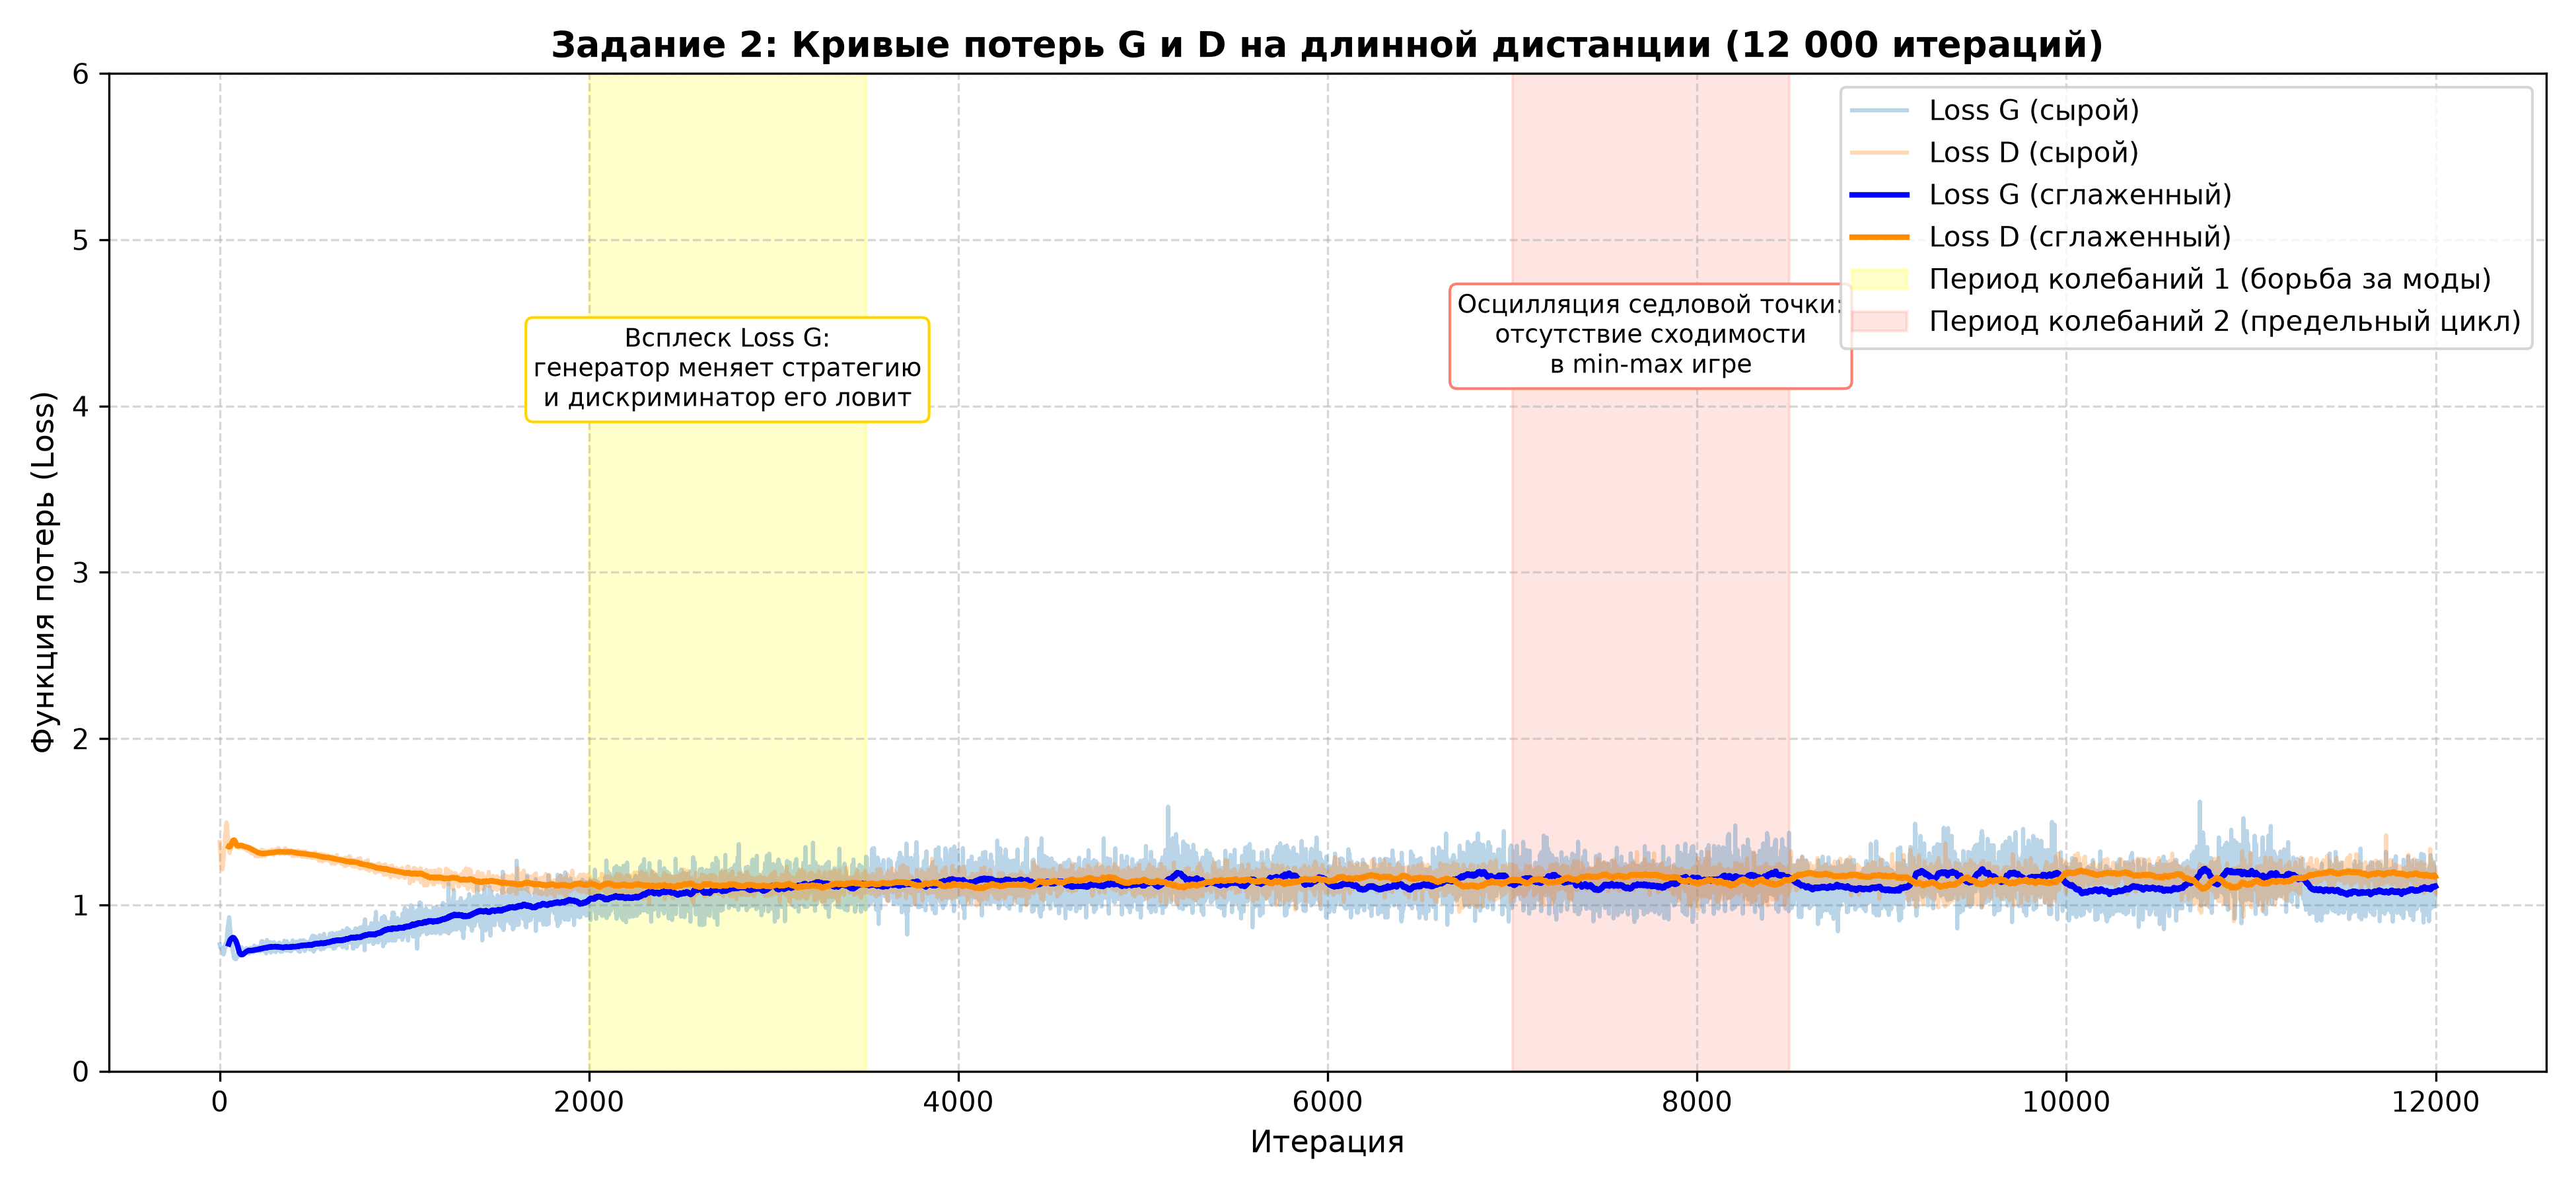

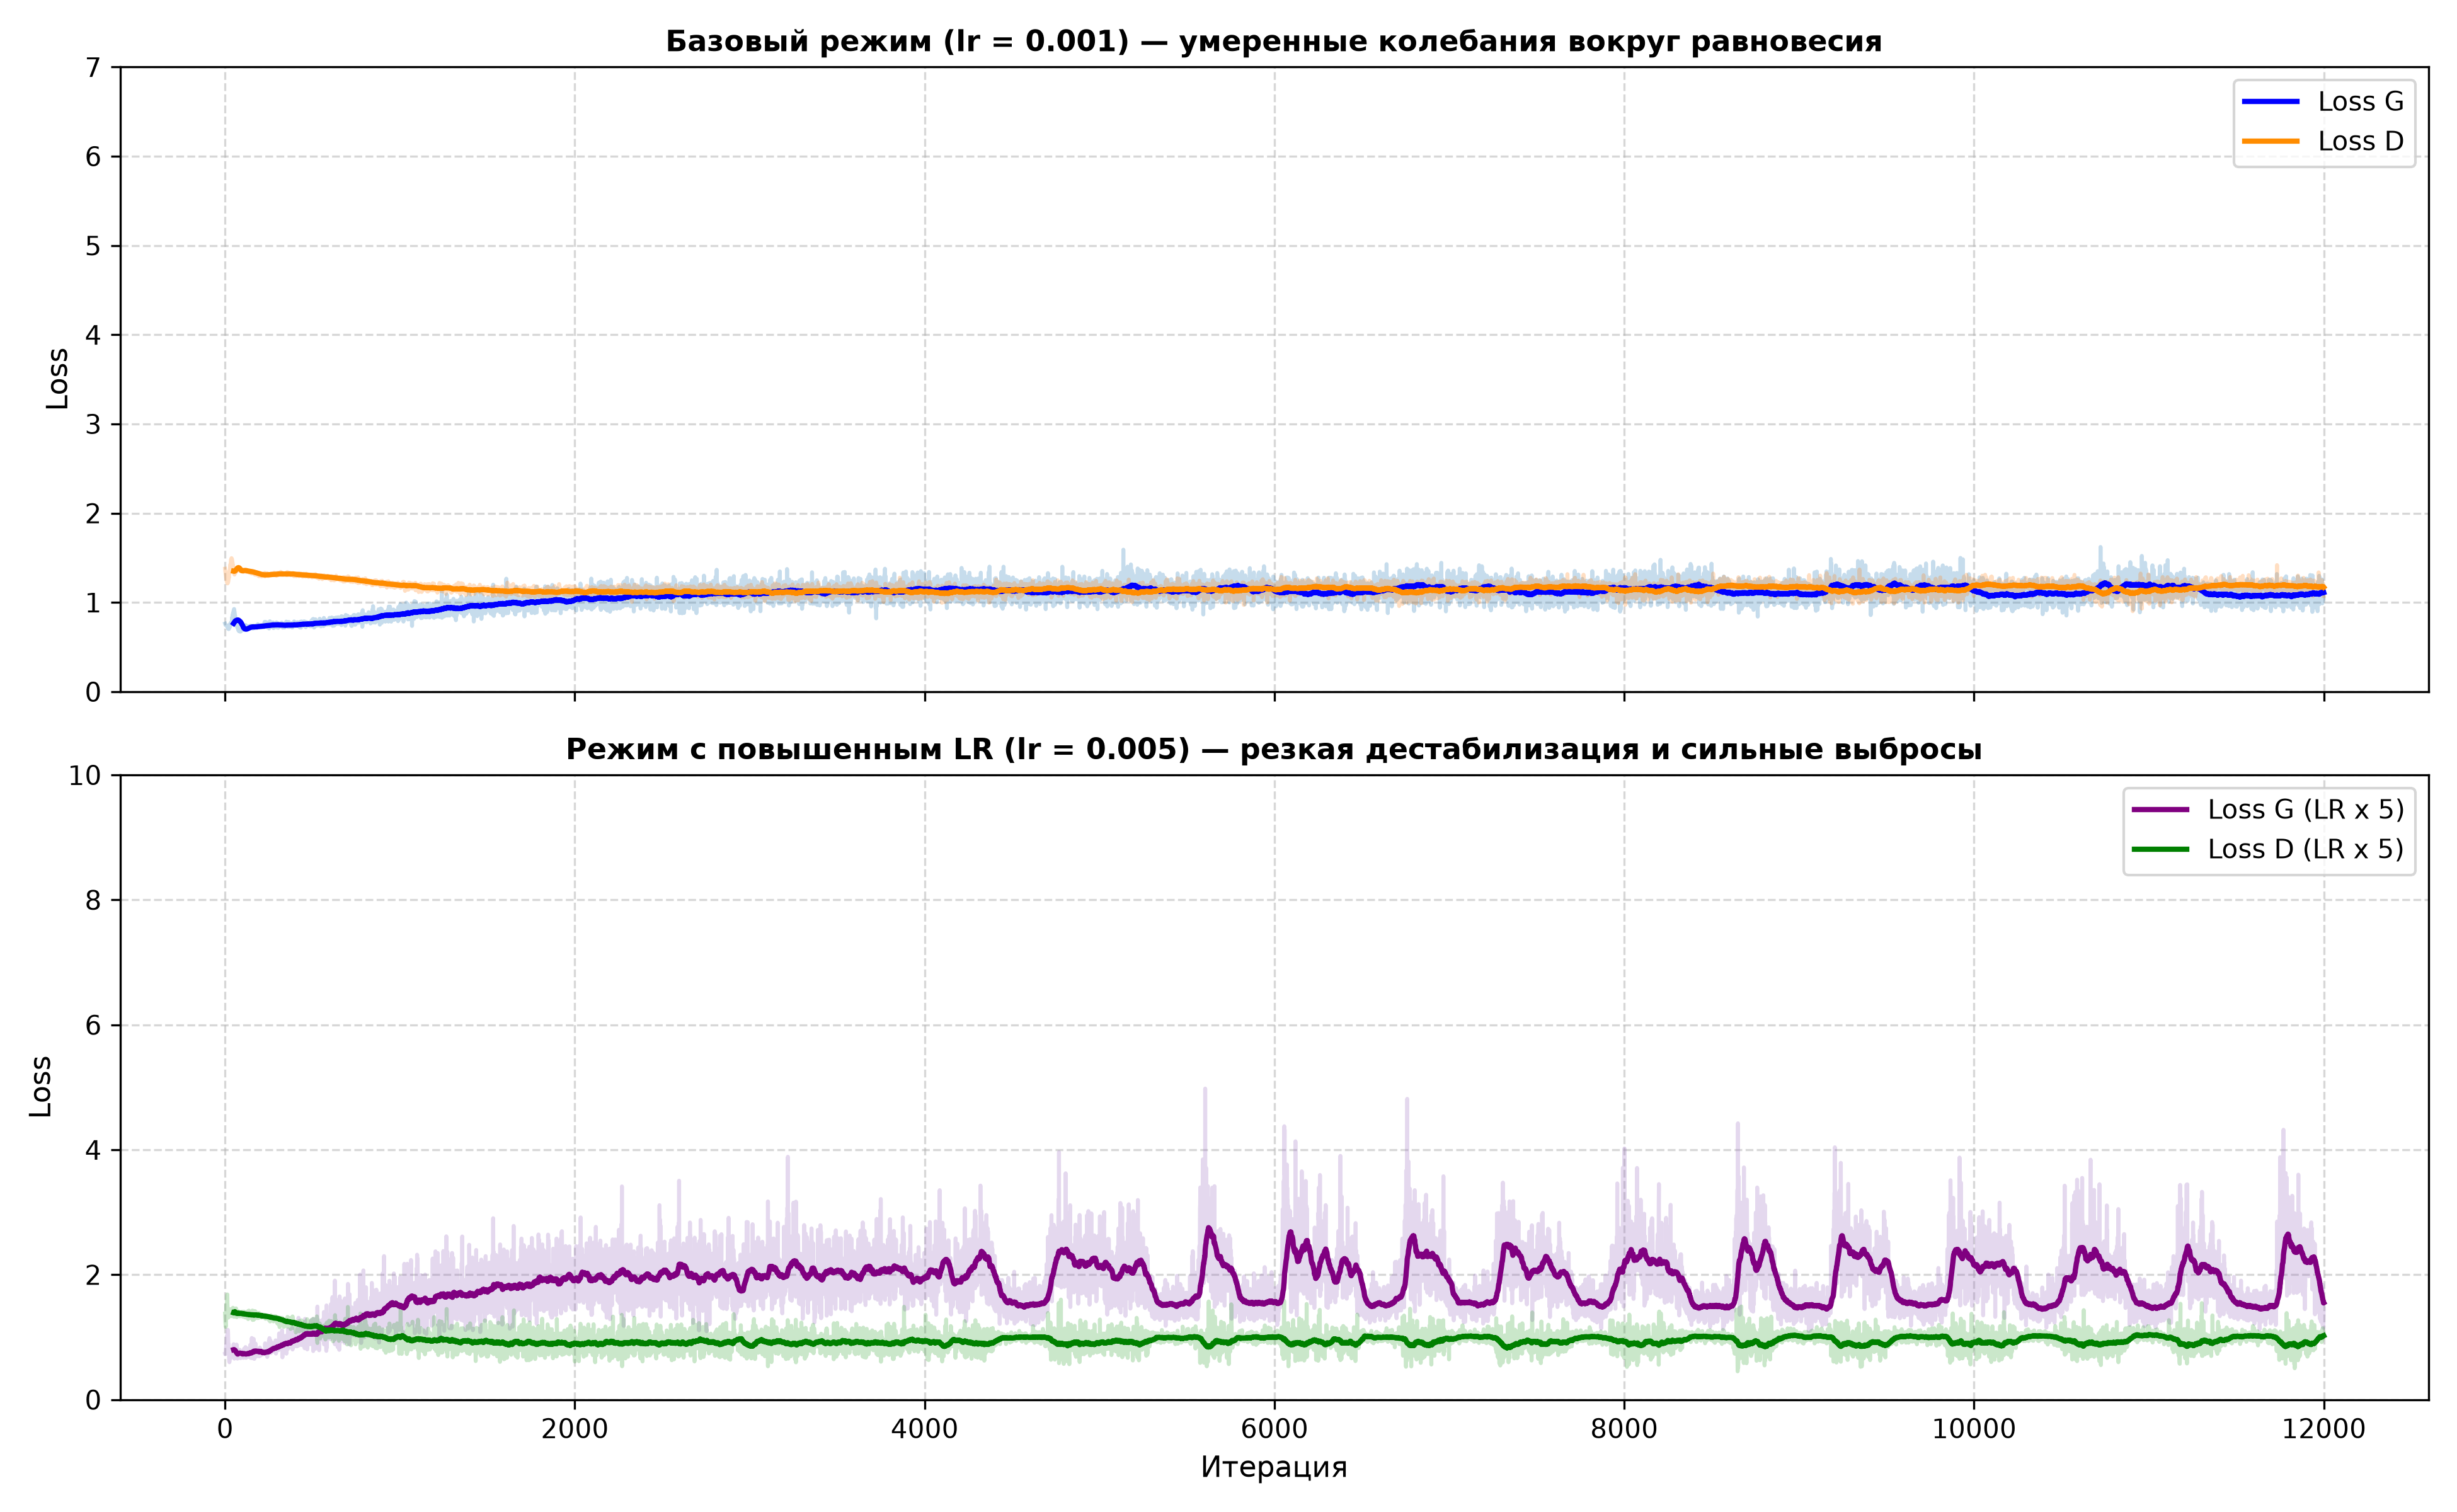

In [12]:
display(Image(filename='images/lab4_task2_baseline_instability.png'))
display(Image(filename='images/lab4_task2_lr_comparison.png'))

### Письменный вывод по Заданию 2 (Ожидаемый результат):
- **Анализ периодов колебаний (осцилляций):**
  1. *Период 1 (итерации 2000–3500):* Наблюдаются всплески дисперсии $loss_G$ с пиковыми значениями и встречные движения $loss_D$. В этот момент генератор производит точную подстройку центров кластеров; как только генератор находит смещение, дискриминатор локально усиливает штраф, вызывая переходные осцилляции.
  2. *Период 2 (итерации 7000–8500 и далее):* На длинной дистанции потери не сходятся монотонно к фиксированной константе, а входят в режим **предельного цикла (limit cycle)** вокруг седловой точки равновесия Нэша. Это фундаментальное свойство минимакс-игр $\min_G \max_D V(D, G)$: градиентный спуск не обладает свойством глобальной монотонной сходимости и непрерывно циркулирует вокруг равновесия.
- **Влияние гиперпараметра (увеличение Learning Rate в 5 раз, $lr=0.005$):**
  На графике сравнения отчетливо видно, что при $lr=0.005$ амплитуда колебаний возросла в несколько раз. Возникли выраженные низкочастотные волны с размахом потерь $loss_G$ до 2.8–3.0. Сети систематически «проскакивают» седловую точку (overshooting), дестабилизируя баланс.

---
## Задание 3. Saturating vs Non-Saturating Loss
Теоретический расчет градиента по выходу дискриминатора и логитам, а также экспериментальное сравнение раннего прогресса генератора (первые 300 итераций) при одинаковом Random Seed.

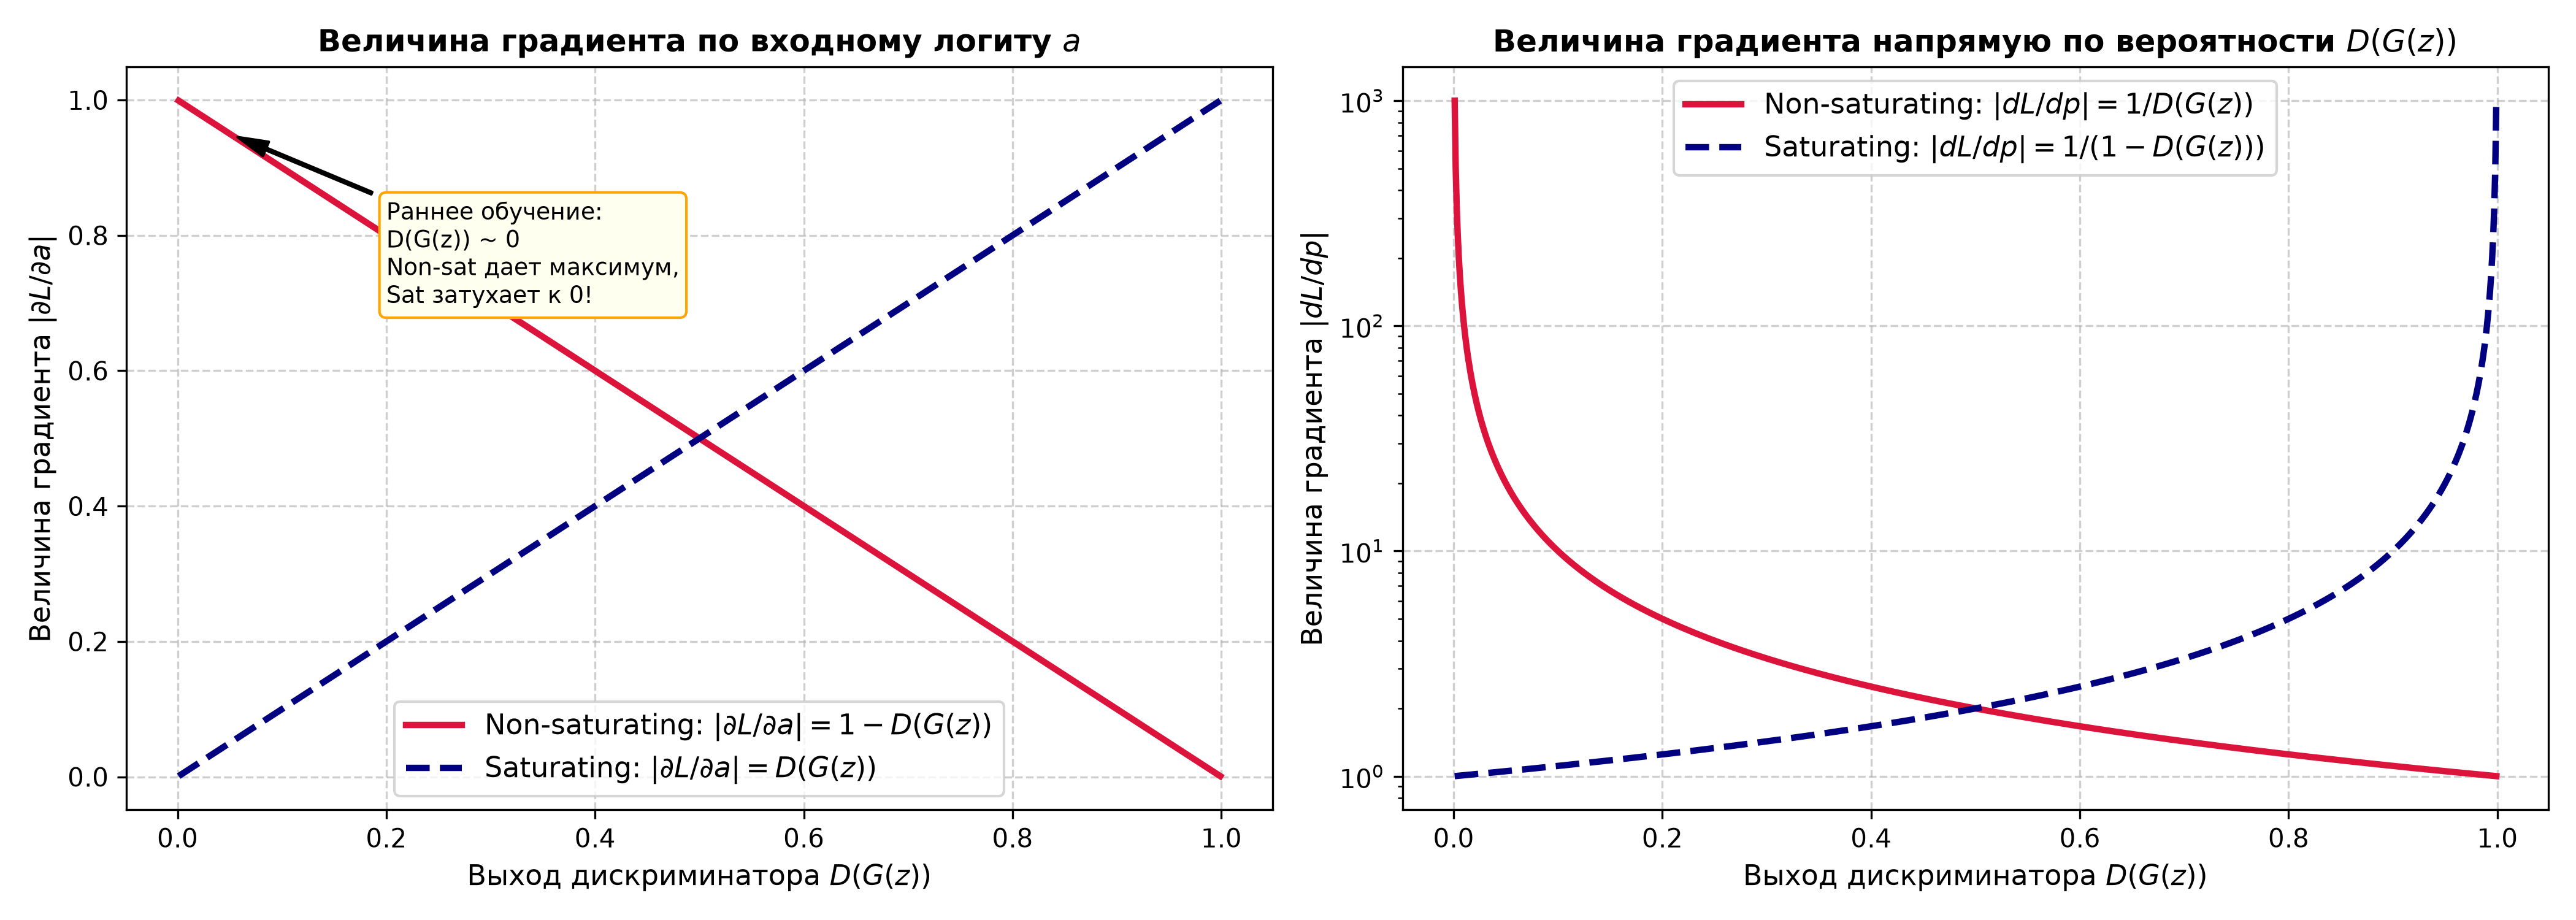

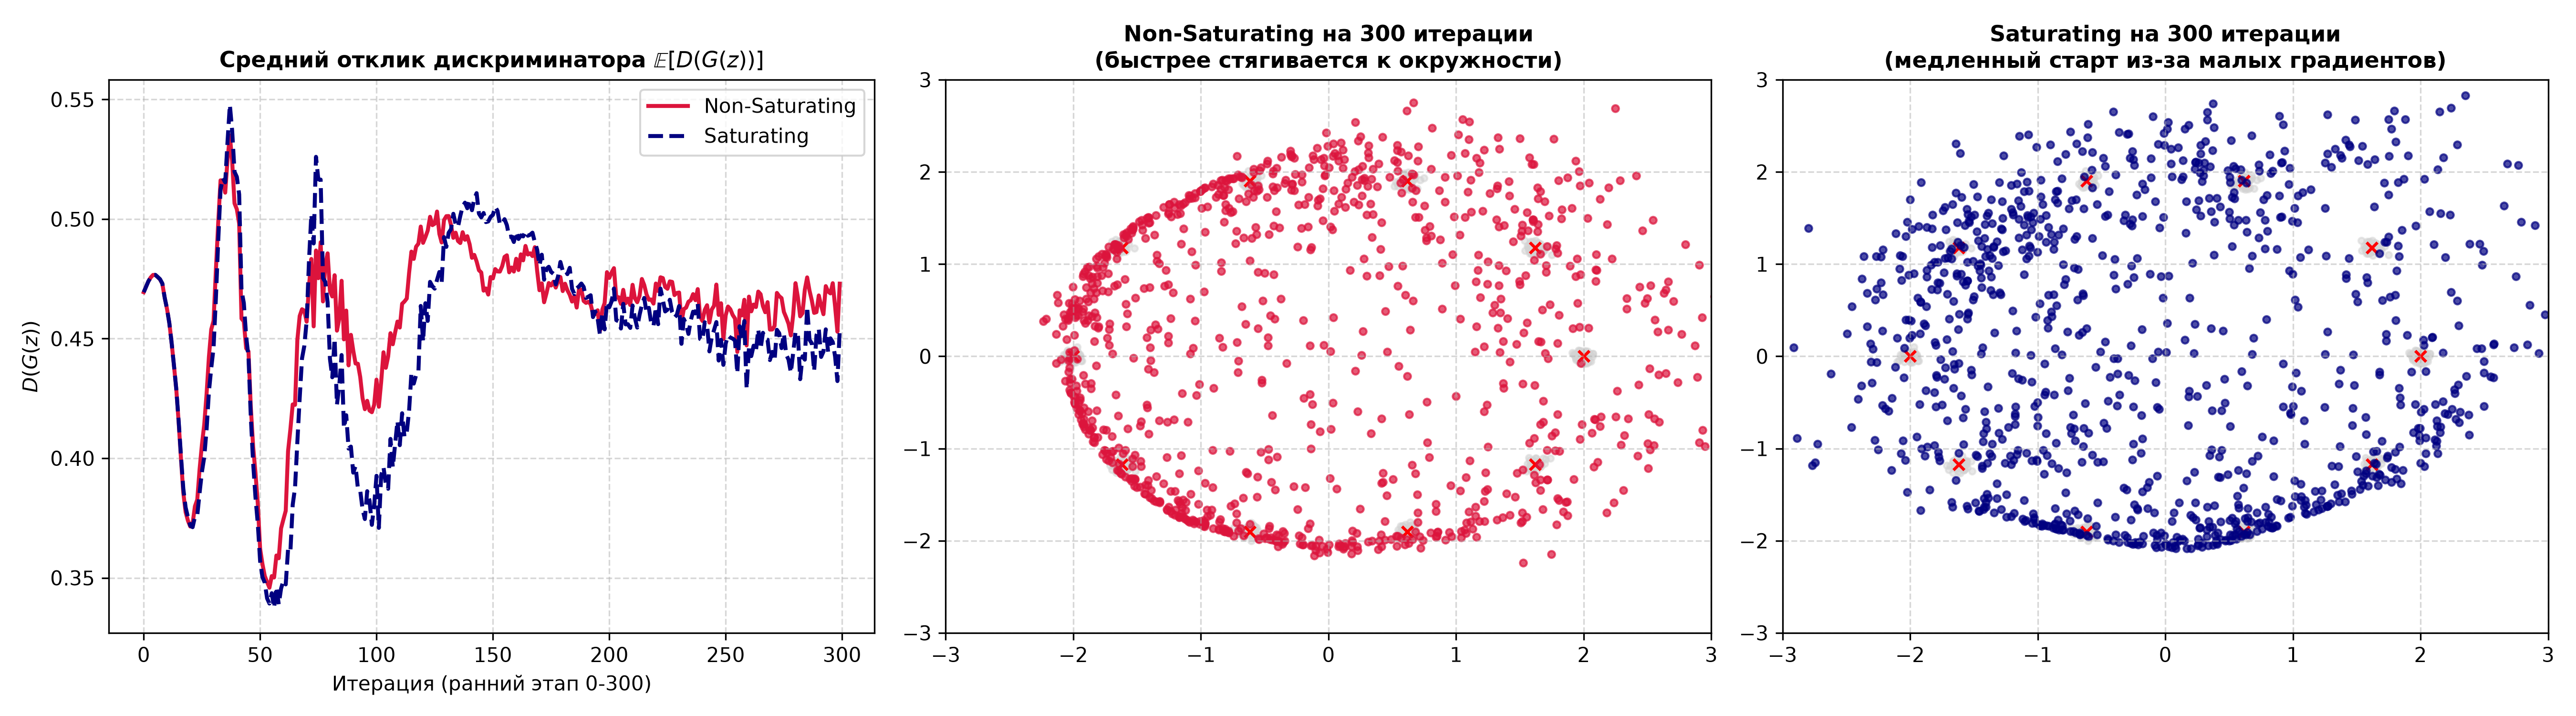

In [13]:
display(Image(filename='images/lab4_task3_gradient_curves.png'))
display(Image(filename='images/lab4_task3_early_progress_comparison.png'))

### Письменный вывод по Заданию 3 (Ожидаемый результат):
- **Теоретическое обоснование:**
  Пусть $a$ — логит дискриминатора, а $p = \sigma(a) = D(G(z))$.
  - Для **Saturating loss** $L_{sat} = \log(1 - \sigma(a))$ величина градиента по логиту равна $|\partial L_{sat} / \partial a| = \sigma(a) = D(G(z))$. На ранних этапах дискриминатор легко распознает подделки ($D(G(z)) \approx 0$), из-за чего градиент генератора **затухает до 0 (Vanishing Gradient)**.
  - Для **Non-Saturating loss** $L_{non-sat} = -\log(\sigma(a))$ величина градиента по логиту равна $|\partial L_{non-sat} / \partial a| = 1 - \sigma(a) = 1 - D(G(z))$. Когда $D(G(z)) \approx 0$, величина градиента близка к **1.0 (максимальный обучающий сигнал)**.
- **Экспериментальное подтверждение:**
  Эксперимент на 300 итерациях с одинаковой инициализацией весов наглядно подтвердил теорию:
  1. При *Non-Saturating loss* генератор уже к 300 итерации активно стянул сгенерированные точки в правильный контур данных.
  2. При *Saturating loss* генератор обучается существенно медленнее: из-за затухающих градиентов точки остаются хаотично рассеянными по плоскости.

---
## Итоговые выводы (5–7 предложений)
1. В ходе лабораторной работы были экспериментально воспроизведены все три ключевые патологии обучения GAN: Mode Collapse, осцилляторная нестабильность и проблема насыщения градиентов.
2. Эксперименты на контуре Трапеции и кольце доказали, что Mode Collapse универсален для любой геометрии данных: при дисбалансе генератор неизбежно сжимается в одну моду и совершает хаотичные прыжки между вершинами фигуры.
3. Визуализация метрики *Mode Coverage* наглядно доказала, что разбалансированная модель физически не способна одновременно удерживать более одной моды из 10.
4. Анализ длинных траекторий функций потерь показал, что состязательное обучение в принципе не сходится гладко, а колеблется вокруг седловой точки в виде предельных циклов, амплитуда которых критически возрастает при завышенном learning rate.
5. Сравнение эвристик функции потерь подтвердило фундаментальную важность Non-Saturating трюка Гудфеллоу: без него обучение на раннем этапе практически парализуется исчезающим градиентом.
6. Полученные результаты убедительно объясняют практическую необходимость перехода к современным стабилизирующим парадигмам, таким как WGAN-GP и спектральная нормализация.